<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_2_Regression/Projects/Instructions/Project.2-Housing/Housing-Pass-13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2 - Pass 13: Housing Price Prediction






The project should be done using Regression prediction techniques ( with feature scaling and regularization ) as covered in class.
The goal is to minimize the RMS ***percentage*** error ( root mean squared percentage error - RMSPE ) on your prediction of the house sales price.



Any of the available features can be used in the regression, but a minimum set of variables that do the job should be the ultimate goal.



Be sure to go through the whole data science process and document as such in your Jupyter notebook.



This project will have less direct "To Do" guidance and the progression through the data science process will be more individualized this time around.  We will talk about all the issues during class so you're not going to be out on a ledge with this one, I just want to move you towards performing a data science project on your own eventually.

There are two parts to this data set, both of which are on AWS:

- [Housing Data Dictionary]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Housing%20-%20Data%20Documentation.pdf )
- [Data Set]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv)


In [1]:
! curl -s -I https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv

HTTP/1.1 200 OK
x-amz-id-2: WRPyv3JWVqw4rVCVE1m6gVuLF7l2LSiNeMCah+CMPtfrJL+3EtpdqtF8mSQYQ+5q5dkHdFn/JG/zYV2KkAK5/EQV8hs6fYAH
x-amz-request-id: VX8PYN6VN21Z0MMJ
Server: AmazonS3
Date: Thu, 29 Oct 2026 02:25:24 GMT
Last-Modified: Fri, 06 Oct 2023 04:00:27 GMT
ETag: "76e84c9ee7f6fd4d51276697f81e76e1"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 880420
Content-Type: text/csv



In [2]:
! curl -s https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv | head -2

PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
905101070,20,RL,62.0,14299,Pave,,Reg,Lvl,AllPub,Inside,G

## Problem Definition

### Business Problem

Help investors evaluate whether what features might be a useful factor when assessing a property's potential market value.

### Data Science Problem

Supervised regression

## Data Collection/Sources

### Load Modules

In [3]:
# Import the libraries and modules
from IPython.display import Image

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import statsmodels.api as sm

from sklearn import datasets, metrics, model_selection
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

### Load Data

In [4]:
# Define the data's url as 'url'
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [5]:
# Define the data frame as 'df'
df = pd.read_csv(url)

## Data Cleaning

### Overview

In [6]:
# Display the head - 81 columns
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


In [7]:
# Display the tail - target is the last row
df.tail()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,528292060,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


In [8]:
# See the shape - 2637 rows, 81 columns
df.shape

(2637, 81)

In [9]:
# See how many total entries
df.size

213597

### Summary Statistics

Summary statistics give you a quick overview of the data.  Some items to spot check:
- the Target:
  - look for nulls
    - null will be culled
  - look at min, max, median, and mean
    - is it a categorical field masquerading as a number?
- the Features:
  - numerical
    - look at min, max, median, and mean
      - a min=1 and max=count suggests an ID
  - categorical
    - look at unique and freq
      - freq=1, unique=count suggests an ID
      - freq=count suggests a meaningless feature

In [10]:
# Summary meta-data - our target 'SalePrice' is int64, our feature 'Lot Frontage' is float64
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2637 non-null   int64  
 1   MS SubClass      2637 non-null   int64  
 2   MS Zoning        2637 non-null   object 
 3   Lot Frontage     2188 non-null   float64
 4   Lot Area         2637 non-null   int64  
 5   Street           2637 non-null   object 
 6   Alley            180 non-null    object 
 7   Lot Shape        2637 non-null   object 
 8   Land Contour     2637 non-null   object 
 9   Utilities        2637 non-null   object 
 10  Lot Config       2637 non-null   object 
 11  Land Slope       2637 non-null   object 
 12  Neighborhood     2637 non-null   object 
 13  Condition 1      2637 non-null   object 
 14  Condition 2      2637 non-null   object 
 15  Bldg Type        2637 non-null   object 
 16  House Style      2637 non-null   object 
 17  Overall Qual  

In [11]:
# See the summary statistics
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
PID,2637.0,7.141301e+08,1.887527e+08,526301100.0,5.284770e+08,535453040.0,9.071870e+08,1.007100e+09
MS SubClass,2637.0,5.734926e+01,4.249909e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2188.0,6.916682e+01,2.335678e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2637.0,1.004469e+04,6.742550e+03,1300.0,7.436000e+03,9450.0,1.152600e+04,1.646600e+05
Overall Qual,2637.0,6.097459e+00,1.411522e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2637.0,5.569966e+00,1.118262e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2637.0,1.971289e+03,3.030699e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2637.0,1.984203e+03,2.091308e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2614.0,1.018879e+02,1.795782e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03
BsmtFin SF 1,2636.0,4.384412e+02,4.496023e+02,0.0,0.000000e+00,368.0,7.320000e+02,5.644000e+03


### Nulls & Identifier Columns

#### Target Nulls


The target should be the first field that you look at.  Its data type will tell you what kind of machine learning problem this is ( classification or regression. ) Any nulls should be culled.  You can check for any skew in the data set.

In [12]:
# Define the name of the target column 'SalePrice' to work with it independently
target_col = 'SalePrice'
df[target_col]

,SalePrice
0,115400
1,90000
2,141000
3,254000
4,155000
...,...
2632,114500
2633,162000
2634,211500
2635,165000


In [13]:
# Look for nulls in the target 'SalePrice' (dropping rows if 20% nulls or under) - no nulls in the target
df[target_col].isnull().sum() / df[target_col].shape[0] * 100


np.float64(0.0)

#### Feature Nulls

In [14]:
# Define the name of the feature columns to work with them independently (all floats and integers are features)
# Select all float columns
feature_cols = df.select_dtypes(include=['float','int']).columns

# Drop the target column from the feature column names
feature_cols = feature_cols.drop(target_col, errors='ignore')

df[feature_cols]

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,905101070,20,62.0,14299,4,3,1964,1964,0.0,513.0,...,440.0,0,0,0,0,0,0,0,7,2007
1,905101330,90,72.0,10791,4,5,1967,1967,0.0,0.0,...,516.0,0,0,0,0,0,0,500,10,2006
2,903454090,50,50.0,9000,6,6,1937,1950,0.0,0.0,...,544.0,0,162,0,0,126,0,0,12,2007
3,533244030,60,68.0,7379,8,5,2000,2000,0.0,484.0,...,592.0,280,184,0,0,0,0,0,4,2010
4,909252020,70,60.0,7200,7,9,1936,2007,0.0,350.0,...,576.0,256,0,0,0,0,0,0,4,2009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,52.0,6240,6,6,1934,1950,0.0,0.0,...,528.0,112,0,0,0,0,0,400,9,2006
2633,906201021,80,74.0,10778,7,6,1990,1991,0.0,460.0,...,462.0,114,36,0,0,0,0,0,7,2009
2634,533253070,120,61.0,3782,8,5,1981,1981,0.0,960.0,...,484.0,133,78,0,0,0,0,0,9,2009
2635,527376100,20,78.0,10140,6,5,1974,1974,174.0,0.0,...,478.0,0,0,0,0,0,0,0,8,2009


In [15]:
# Look for nulls in the features (dropping rows if 20% nulls or under) - 17% is the highest proportion of nulls in 'Lot Frontage'
(df[feature_cols].isnull().sum() / df[feature_cols].shape[0] * 100).sort_values(ascending=False)

,0
Lot Frontage,17.026925
Garage Yr Blt,5.574516
Mas Vnr Area,0.872203
Bsmt Half Bath,0.075844
Bsmt Full Bath,0.075844
Garage Cars,0.037922
Garage Area,0.037922
BsmtFin SF 2,0.037922
Bsmt Unf SF,0.037922
Total Bsmt SF,0.037922


#### Identifier Columns

In [16]:
# See proportion of unique values in the target column
(df[target_col].nunique() / df[target_col].shape[0] * 100) #.sort_values(ascending=False)

37.2772089495639

In [17]:
# See proportion of unique values in the feature columns
(df[feature_cols].nunique() / df[feature_cols].shape[0] * 100).sort_values(ascending=False)

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
Bsmt Unf SF,40.955631
1st Flr SF,38.756162
Total Bsmt SF,37.959803
BsmtFin SF 1,35.456959
2nd Flr SF,22.335988
Garage Area,21.843003
Mas Vnr Area,16.116799


In [18]:
# See the data types of the features - continuous are good for linear regression
df[feature_cols].dtypes.sort_values()

,0
PID,int64
Misc Val,int64
Pool Area,int64
Screen Porch,int64
3Ssn Porch,int64
Enclosed Porch,int64
Open Porch SF,int64
Wood Deck SF,int64
Fireplaces,int64
TotRms AbvGrd,int64


In [19]:
# See the data types of the target - continuous are good for linear regression
df[target_col].dtypes

dtype('int64')

### Backup #1

In [20]:
# Make a backup
df_bak1 = df.copy()

In [21]:
# Restore from backup
df = df_bak1.copy()

### Cull the Nulls

Feature column containing 17% nulls, so drop those rows in our dataset.

In [22]:
# Drop null rows referencing the feature columns
df = df.dropna(subset=feature_cols)

In [23]:
# Verify rows dropped
df.shape

(2033, 81)

In [24]:
# Verify no nulls in feature columns
df[feature_cols].isnull().sum()

,0
PID,0
MS SubClass,0
Lot Frontage,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
Mas Vnr Area,0
BsmtFin SF 1,0


### Backup #2

In [25]:
# Make a backup
df_bak2 = df.copy()

In [26]:
# Restore from backup
df = df_bak2.copy()

In [27]:
# Verify the shape (37 feature columns)
df[feature_cols].shape

(2033, 37)

### Drop Identifier Column

In [28]:
# Drop the identifier column 'PID'
id_col = 'PID'

df = df.drop(columns=id_col)

df.shape

(2033, 80)

In [29]:
# Define the name of the feature columns to work with them independently (all floats and integers are features)
# Select all float columns
feature_cols = df.select_dtypes(include=['float','int']).columns

# Drop the target column from the feature column names
feature_cols = feature_cols.drop(target_col, errors='ignore')

df[feature_cols]

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,20,62.0,14299,4,3,1964,1964,0.0,513.0,144.0,...,440.0,0,0,0,0,0,0,0,7,2007
1,90,72.0,10791,4,5,1967,1967,0.0,0.0,0.0,...,516.0,0,0,0,0,0,0,500,10,2006
2,50,50.0,9000,6,6,1937,1950,0.0,0.0,0.0,...,544.0,0,162,0,0,126,0,0,12,2007
3,60,68.0,7379,8,5,2000,2000,0.0,484.0,0.0,...,592.0,280,184,0,0,0,0,0,4,2010
4,70,60.0,7200,7,9,1936,2007,0.0,350.0,210.0,...,576.0,256,0,0,0,0,0,0,4,2009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,50,52.0,6240,6,6,1934,1950,0.0,0.0,0.0,...,528.0,112,0,0,0,0,0,400,9,2006
2633,80,74.0,10778,7,6,1990,1991,0.0,460.0,286.0,...,462.0,114,36,0,0,0,0,0,7,2009
2634,120,61.0,3782,8,5,1981,1981,0.0,960.0,0.0,...,484.0,133,78,0,0,0,0,0,9,2009
2635,20,78.0,10140,6,5,1974,1974,174.0,0.0,0.0,...,478.0,0,0,0,0,0,0,0,8,2009


### Backup #3

In [30]:
# Make a backup
df_bak3 = df.copy()

In [31]:
# Restore from backup
df = df_bak3.copy()

### Cleaned Data Frame

In [32]:
# Define our target and feature columns as a data frame to work with 'df_clean'
df_clean = pd.concat([df[target_col], df[feature_cols]], axis=1).reset_index(drop=True)

In [33]:
# Verify the working data frame
df_clean

,SalePrice,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,115400,20,62.0,14299,4,3,1964,1964,0.0,513.0,...,440.0,0,0,0,0,0,0,0,7,2007
1,90000,90,72.0,10791,4,5,1967,1967,0.0,0.0,...,516.0,0,0,0,0,0,0,500,10,2006
2,141000,50,50.0,9000,6,6,1937,1950,0.0,0.0,...,544.0,0,162,0,0,126,0,0,12,2007
3,254000,60,68.0,7379,8,5,2000,2000,0.0,484.0,...,592.0,280,184,0,0,0,0,0,4,2010
4,155000,70,60.0,7200,7,9,1936,2007,0.0,350.0,...,576.0,256,0,0,0,0,0,0,4,2009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2028,114500,50,52.0,6240,6,6,1934,1950,0.0,0.0,...,528.0,112,0,0,0,0,0,400,9,2006
2029,162000,80,74.0,10778,7,6,1990,1991,0.0,460.0,...,462.0,114,36,0,0,0,0,0,7,2009
2030,211500,120,61.0,3782,8,5,1981,1981,0.0,960.0,...,484.0,133,78,0,0,0,0,0,9,2009
2031,165000,20,78.0,10140,6,5,1974,1974,174.0,0.0,...,478.0,0,0,0,0,0,0,0,8,2009


## EDA (Exploratory Data Analysis)

### Feature Selection

Use standard scaler to scale data set.

This data set is the cleaned without the feature selection from correlation.

In [34]:
# Define out target and features
X_all_features = df_clean.drop(target_col, axis = 1)
y_target = df_clean[target_col]

In [41]:
# Specify values of alpha we want to try
alpha = [50, 75, 100, 200, 300, ]

# Create empty list to hold results
results_alpha = []

for a in alpha:
  # Calculate CV RMSE
  n = 200
  results = np.zeros(n)

  for idx in range(n):
    # Train, test split
    X_train, X_test, y_train, y_test = train_test_split(X_all_features, y_target, test_size=0.25)

    # Standard scale only training features
    scaler = StandardScaler()
    scaler.fit(X_train)
    X_train_scaled = scaler.transform(X_train)

    # Scale testing features
    X_test_scaled = scaler.transform(X_test)

    # Create the model
    model_lasso = Lasso(alpha = a, tol = .01, max_iter=10_000); # Looping through alpha

    # Fit regression
    model_lasso.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model_lasso.predict(X_test_scaled)

    # Calculate and record performance metric
    results[idx] = np.sqrt(mean_squared_error(y_test,y_pred))

  results_alpha.append(results.mean())

results_df = pd.DataFrame({'Alpha': alpha, 'RMSE': results_alpha})


In [42]:
results_df.sort_values( by = 'RMSE' )


,Alpha,RMSE
4,300,33489.692934
0,50,34305.175493
3,200,34487.449464
1,75,34660.335485
2,100,34794.041145


Get the Alpha that results in the lowest RMSE.

In [43]:
results_df.sort_values( by = 'RMSE' )["Alpha"][0]


np.int64(50)

In [44]:
results_df.sort_values( by = 'RMSE' )["Alpha"].iloc[0]


np.int64(300)

In [46]:
a = results_df.sort_values( by = 'RMSE' )["Alpha"].iloc[0]
a

np.int64(300)

In [50]:
# %%capture --no-stdout
# Perform CV
n = 500
results = np.zeros(n)

for idx in range(n):
  # Train, test split
  X_train, X_test, y_train, y_test = train_test_split(X_all_features, y_target, test_size=0.25)

  # Standard scale only training features
  scaler = StandardScaler()
  scaler.fit(X_train)
  X_train_scaled = scaler.transform(X_train)

  # Scale testing features
  X_test_scaled = scaler.transform(X_test)

  # Create the model
  model_lasso = Lasso(alpha = a, tol = .01, max_iter=10000)

  # Fit regression
  model_lasso.fit(X_train, y_train)

  # Predict
  y_pred = model_lasso.predict(X_test)

  # Calculate and record performance metric
  results[idx] = np.sqrt(mean_squared_error(y_test,y_pred))

print(f"CV RMSE: {results.mean().round(2)}")
print(f"Number of Predictors: {sum(model_lasso.coef_ >0)}")

CV RMSE: 34662.49
Number of Predictors: 25


In [52]:
X_all_features.shape

(2033, 36)

In [53]:
len(X_all_features.columns)

36

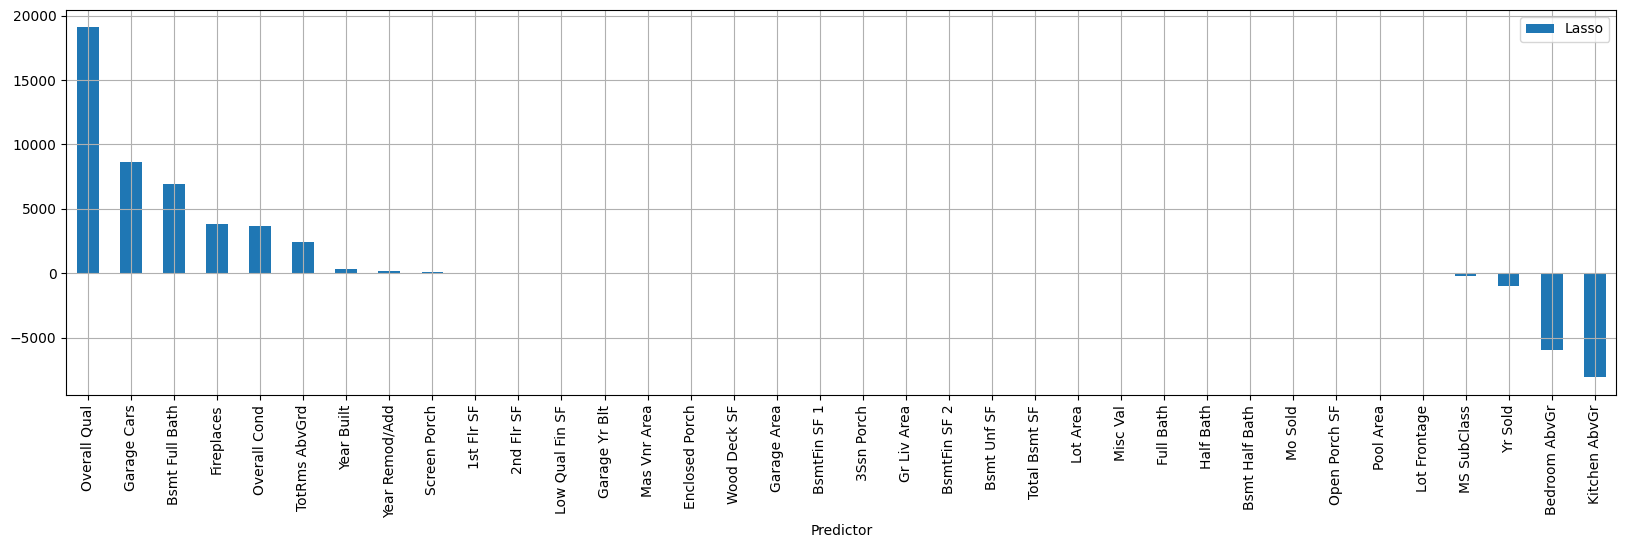

In [54]:
# Plot model coefficients
model_results = pd.DataFrame()
model_results['Predictor'] = X_all_features.columns
model_results['Lasso'] = model_lasso.coef_
model_results.sort_values( by = ["Lasso"], ascending = False ).plot(
    x = 'Predictor',
    kind = 'bar',
    figsize = (20,5)
    )
plt.grid()

In [55]:
model_results['Lasso'].abs().sort_values()

,Lasso
18,0.000000
19,0.000000
17,0.000000
34,0.000000
33,0.033518
2,0.252471
11,2.288753
10,3.112967
9,7.243484
15,7.758723


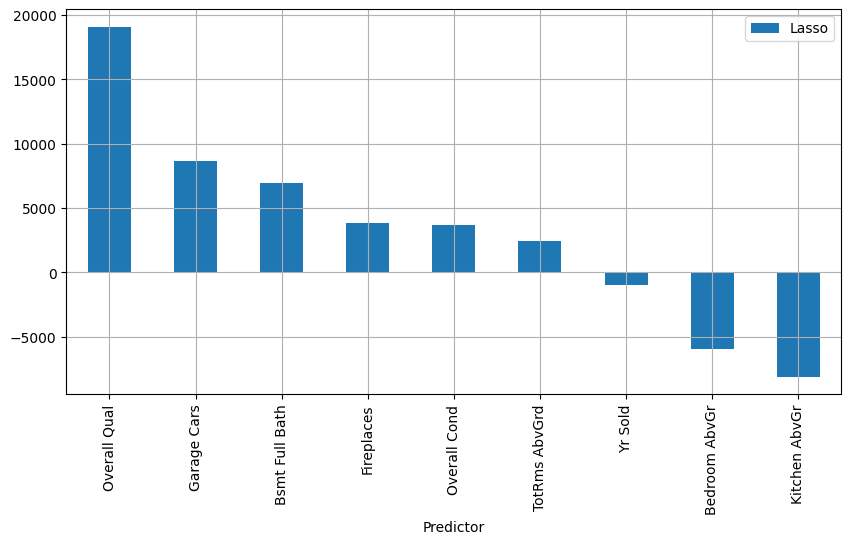

In [56]:
# Plot parameters with coefficients greater than 0
greater_0 = model_results[(model_results['Lasso'] > 500 ) | (model_results['Lasso'] < -500 )]
greater_0.sort_values( by = ["Lasso"], ascending = False ).plot(x = 'Predictor', kind = 'bar', figsize = (10,5))
plt.grid()

In [67]:
X_features_work = X_all_features[greater_0["Predictor"]]

### Working Data Frame

In [71]:
df_work = pd.concat([df_clean[target_col], X_features_work], axis=1).reset_index(drop=True)

In [72]:
df_work

,SalePrice,Overall Qual,Overall Cond,Bsmt Full Bath,Bedroom AbvGr,Kitchen AbvGr,TotRms AbvGrd,Fireplaces,Garage Cars,Yr Sold
0,115400,4,3,1.0,3,1,5,0,2.0,2007
1,90000,4,5,0.0,2,2,6,0,2.0,2006
2,141000,6,6,0.0,3,1,6,1,1.0,2007
3,254000,8,5,1.0,3,1,7,1,2.0,2010
4,155000,7,9,1.0,3,1,6,0,2.0,2009
...,...,...,...,...,...,...,...,...,...,...
2028,114500,6,6,0.0,3,1,6,1,2.0,2006
2029,162000,7,6,1.0,1,1,4,0,2.0,2009
2030,211500,8,5,1.0,1,1,4,2,2.0,2009
2031,165000,6,5,0.0,3,1,7,1,2.0,2009


## Data Processing

Prepare Data Frame (Target and Features)

In [73]:
# Define out the target and feature columns from our cleaned working data frame
print(X_features_work)
print(df_work[target_col])

      Overall Qual  Overall Cond  Bsmt Full Bath  Bedroom AbvGr  \
0                4             3             1.0              3   
1                4             5             0.0              2   
2                6             6             0.0              3   
3                8             5             1.0              3   
4                7             9             1.0              3   
...            ...           ...             ...            ...   
2028             6             6             0.0              3   
2029             7             6             1.0              1   
2030             8             5             1.0              1   
2031             6             5             0.0              3   
2032             7             5             0.0              4   

      Kitchen AbvGr  TotRms AbvGrd  Fireplaces  Garage Cars  Yr Sold  
0                 1              5           0          2.0     2007  
1                 2              6           0       

#### Performance

Performance metric is RMSPE

In [75]:
# Define a function to calculate RMSPE
def rmspe(y_true, y_pred):
    return np.sqrt(np.mean(((y_true - y_pred) / y_true) ** 2)) * 100


Multi CV with range of alphas

In [81]:

# Specify values of alpha we want to try
alpha = [0.001, 0.01, 0.1, 1, 5, 10, 25, 50, 75, 100, 250, 500, 1000]

# Create empty list to hold results
results_alpha = []

for a in alpha:

    # Calculate CV RMSPE
    n = 100
    results = np.zeros(n)

    for idx in range(n):

        # Train, test split
        X_train, X_test, y_train, y_test = train_test_split(
            X_features_work, y_target, test_size=0.25
        )

        # Standard scale only training features
        scaler = StandardScaler()
        scaler.fit(X_train)
        X_train_scaled = scaler.transform(X_train)

        # Scale testing features
        X_test_scaled = scaler.transform(X_test)

        # Create the Lasso model
        my_fit_lasso = Lasso(
            alpha=a, tol=0.01, max_iter=10_000
        )

        # Fit regression
        my_fit_lasso.fit(X_train_scaled, y_train)

        # Predict
        y_pred = my_fit_lasso.predict(X_test_scaled)

        # Calculate and record RMSPE
        results[idx] = rmspe(y_test, y_pred)

    # Record average RMSPE for this alpha
    results_alpha.append(results.mean())

# Create results DataFrame
results_df = pd.DataFrame({
    'Alpha': alpha,
    'RMSPE': results_alpha
})

In [82]:
# Create results DataFrame
results_df = pd.DataFrame({
    'Alpha': alpha,
    'RMSPE': results_alpha
})

# Print results
print(results_df)

       Alpha      RMSPE
0      0.001  23.266075
1      0.010  23.795140
2      0.100  23.511687
3      1.000  23.184771
4      5.000  23.021884
5     10.000  23.582579
6     25.000  23.380199
7     50.000  23.513620
8     75.000  23.064690
9    100.000  23.488567
10   250.000  23.572314
11   500.000  23.506138
12  1000.000  23.335690


In [83]:
# Sort from lowest to highest RMSPE
print(results_df.sort_values(by='RMSPE'))

       Alpha      RMSPE
4      5.000  23.021884
8     75.000  23.064690
3      1.000  23.184771
0      0.001  23.266075
12  1000.000  23.335690
6     25.000  23.380199
9    100.000  23.488567
11   500.000  23.506138
2      0.100  23.511687
7     50.000  23.513620
10   250.000  23.572314
5     10.000  23.582579
1      0.010  23.795140


<Axes: >

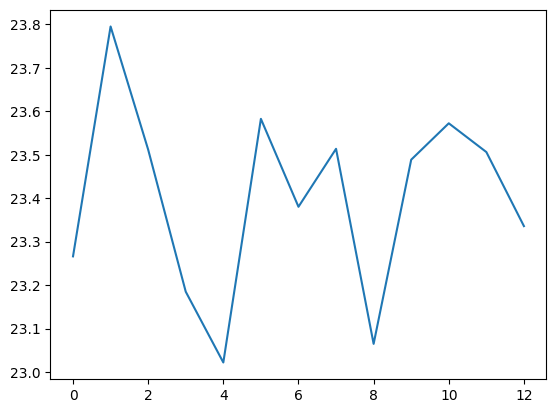

In [86]:
# Plot of alphas by RMSPE
results_df.sort_values( by = ["Alpha"])["RMSPE"].plot()

Repeat multi CV with selected alpha

In [84]:
# Specify the number of CV iterations
n = 100

# Create an empty array to hold RMSPE results
results = np.zeros(n)

for idx in range(n):

    # Train, test split
    X_train, X_test, y_train, y_test = train_test_split(
        X_features_work, y_target, test_size=0.25
    )

    # Standard scale only training features
    scaler = StandardScaler()
    scaler.fit(X_train)
    X_train_scaled = scaler.transform(X_train)

    # Scale testing features
    X_test_scaled = scaler.transform(X_test)

    # Create the Lasso model using the best alpha
    my_fit_lasso = Lasso(
        alpha=5,
        tol=0.01,
        max_iter=10_000
    )

    # Fit regression
    my_fit_lasso.fit(X_train_scaled, y_train)

    # Predict
    y_pred = my_fit_lasso.predict(X_test_scaled)

    # Calculate and record RMSPE
    results[idx] = rmspe(y_test, y_pred)

# Calculate average RMSPE
mean_rmspe = results.mean()

# Display the average RMSPE
print("Multi CV Average RMSPE:", mean_rmspe)


Multi CV Average RMSPE: 23.44606494166484


''

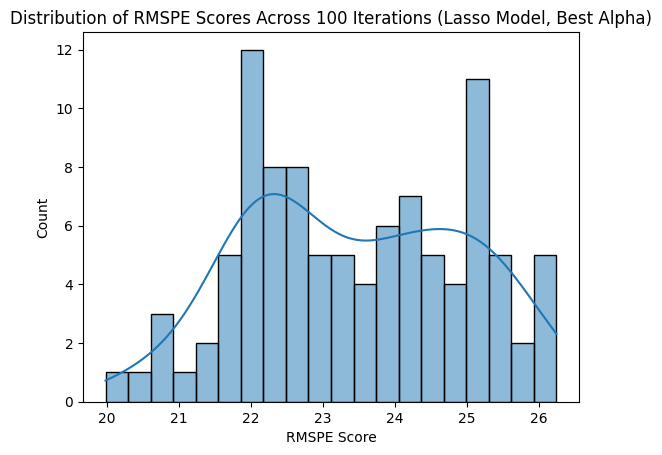

In [87]:
# Display a histogram of the multi CV results with alpha = chosen alpha
sns.histplot(results, kde=True, bins=20)
plt.title('Distribution of RMSPE Scores Across 100 Iterations (Lasso Model, Best Alpha)')
plt.xlabel('RMSPE Score')
plt.ylabel('Count')
;

## Data Visualization

#### Residual Analysis

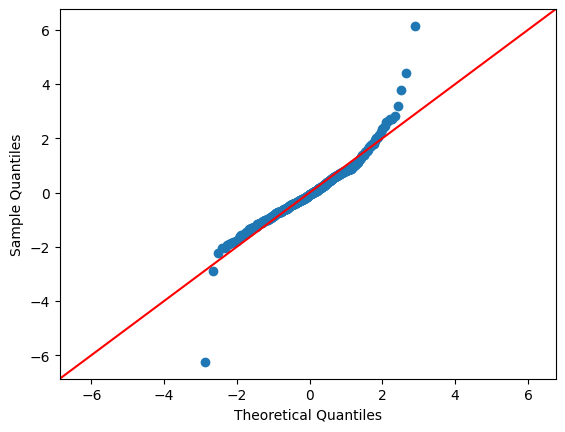

In [91]:
# QQ Plot - Residuals are not normally distributed
res = y_test - y_pred
sm.qqplot(res, fit=True, line="45") ;

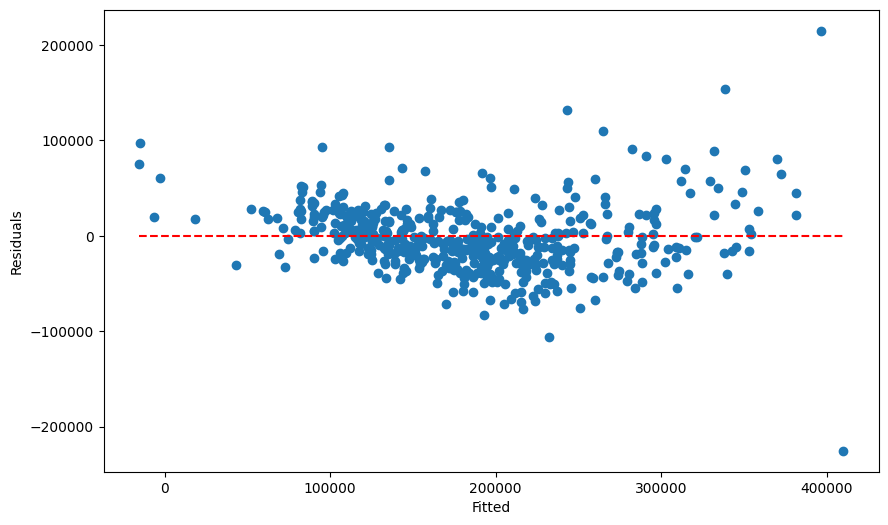

In [92]:
# Residuals vs Fitted (Predicted) Values - Constant variance
plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted")
plt.ylabel("Residuals")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;

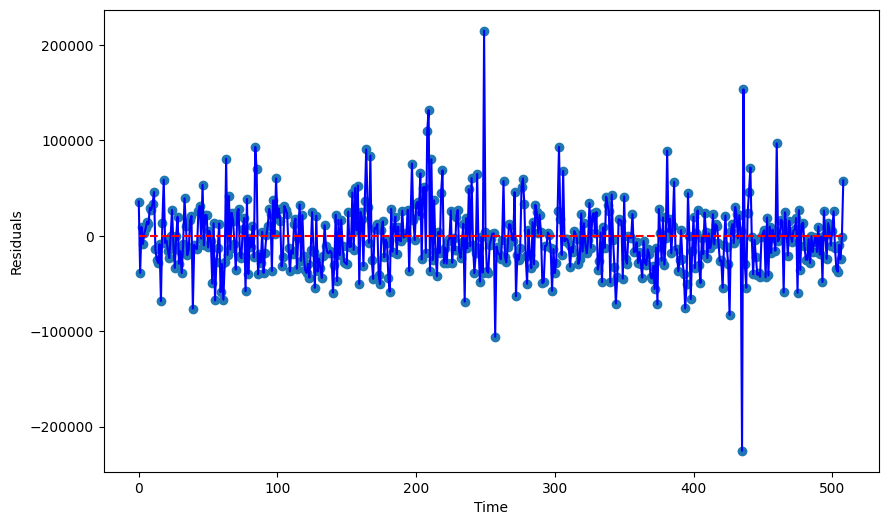

In [93]:
# Residuals vs Time - indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;

In [94]:
# Lasso Regression - prediction performance stats
print("Mean RMSPE:", np.mean(results))
print("Standard deviation:", np.std(results))
print("Minimum RMSPE:", np.min(results))
print("Maximum RMSPE:", np.max(results))

Mean RMSPE: 23.44606494166484
Standard deviation: 1.5260389033547002
Minimum RMSPE: 19.986675605708676
Maximum RMSPE: 26.24818027523047


## Communication of Results

#### Conclusion

Mean RMPSE for Lasso Regression Model: 23.44606494166484

Used lasso regression for feature selection, and then ran those features through a lasso regression.

#### Future Work
- Try different feature selection method
- Try a different prediction model
- Try getting RMPSE lower